# 📊 Data team · How well does the model read new people?

Meta trained a model that turns wrist muscle signals (EMG) into 9 finger and thumb
gestures. Your job: **find out how well it works on people it has never seen, and
explain why it sometimes fails.**

**You hand in** (at the merge):
- `per_user_accuracy.png`: the chart that goes into the live demo
- `findings.md`: 3 short findings for the final slide

**The metric is CLER** (lower is better): of the gestures the model *detects*, the share
it names wrong, averaged over the 9 gesture types. *Gesture accuracy* = 1 − CLER.
**Careful:** CLER doesn't count gestures the model **misses** completely, or extra ones it
invents. Step 3 shows those, and they're a good finding.

**How to use this notebook**
1. **File → Save a copy in Drive.** You now have your own copy. Edit anything.
2. **Runtime → Run all**, or run cells one by one with ▶ / Shift+Enter.
3. The outputs you see before running are from the organizers' run, so you know what to expect.
   On Colab things take longer than shown (about 10× for the big runs).

*Data, model and the code underneath: Meta, [generic-neuromotor-interface](https://github.com/facebookresearch/generic-neuromotor-interface), **CC BY-NC 4.0** (non-commercial, keep the credit). Kaifosh, Reardon & CTRL-labs at Reality Labs, Nature (2025).*

In [ ]:
# @title ⚙️ Setup: run this first (1–2½ min). Double-click to see the code.
import base64, os, subprocess, sys, time, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
WORK = "/content/buildday" if IN_COLAB else os.path.abspath("buildday")
os.makedirs(WORK, exist_ok=True); os.chdir(WORK)
if WORK not in sys.path: sys.path.insert(0, WORK)
_t = time.time()
if "_T0" not in globals(): _T0 = _t   # start of the whole notebook run

FILES = {'requirements.txt': 'IyBXZWFyYWJsZSBBSSBCdWlsZCBEYXkgc3RhcnRlciByZXBvLgojIEluc3RhbGw6ICBwaXAgaW5zdGFsbCAtciByZXF1aXJlbWVudHMudHh0CiMgVGVzdGVkIHdpdGggUHl0aG9uIDMuMTIgKE1hY0Jvb2spIGFuZCBQeXRob24gMy4xMyAoQ29sYWIsIE5vdiAyMDI2KS4KIwojIE5vIHVwcGVyIGJvdW5kcyBvbiB0b3JjaC9udW1weSBvbiBwdXJwb3NlOiBDb2xhYiBhbHJlYWR5IGhhcyByZWNlbnQgdmVyc2lvbnMsCiMgYW5kIHBpbm5pbmcgb2xkIG9uZXMgbWFrZXMgcGlwIGRvd25sb2FkIH4yIEdCIGFuZCByZWluc3RhbGwgUHlUb3JjaC4KCiMgTWV0YSdzIGNvZGUsIHBpbm5lZCB0byB0aGUgY29tbWl0IHdlIHRlc3RlZCBhZ2FpbnN0IChDQyBCWS1OQyA0LjApCmdlbmVyaWNfbmV1cm9tb3Rvcl9pbnRlcmZhY2UgQCBnaXQraHR0cHM6Ly9naXRodWIuY29tL2ZhY2Vib29rcmVzZWFyY2gvZ2VuZXJpYy1uZXVyb21vdG9yLWludGVyZmFjZUBiNmJmMjUwZTJiZTVhNjdiMjM0ODgxMDQzMzUzNzNjZGI4N2ExNWM5CgojIFdoYXQgZW1nX2tpdCBhbmQgTWV0YSdzIGRhdGEvbWV0cmljIG1vZHVsZXMgaW1wb3J0CnRvcmNoPj0yLjQKbnVtcHk+PTEuMjYKbnVtYmE+PTAuNjAKaDVweT49My4xMQpwYW5kYXM+PTIuMgp0YWJsZXM+PTMuMTAgICAgICAgICAgIyBwYW5kYXMucmVhZF9oZGYgbmVlZHMgdGhpcyB0byByZWFkIHRoZSBnZXN0dXJlIGxhYmVscwpvbWVnYWNvbmY+PTIuMwp0b3JjaG1ldHJpY3M+PTAuMTEgICAgIyBpbXBvcnRlZCBieSBNZXRhJ3MgZGF0YSBtb2R1bGUgKGhhbmR3cml0aW5nIHV0aWxzKQpsZXZlbnNodGVpbj49MC4yNQp1bmlkZWNvZGU+PTEuMwpyZXF1ZXN0cwp0cWRtCgojIFBsb3RzLCBub3RlYm9va3MsIGRlbW8KbWF0cGxvdGxpYj49My44CnNlYWJvcm4+PTAuMTMKanVweXRlcmxhYj49NAppcHlrZXJuZWwKbmJmb3JtYXQKZ3JhZGlvPj01CgojIE5vdCBuZWVkZWQ6IHB5dG9yY2gtbGlnaHRuaW5nIC8gaHlkcmEtY29yZS4gVGhleSBhcmUgb25seSBmb3IgTWV0YSdzIHRyYWluaW5nCiMgbG9vcC4gVG8gcnVuIE1ldGEncyBvd24gdHJhaW5lci50ZXN0LCBzZWUgcmVxdWlyZW1lbnRzLW1ldGEudHh0Lgo=', 'emg_kit/__init__.py': '', 'emg_kit/core.py': '...', 'emg_kit/download.py': 'IiIiRG93bmxvYWQgTWV0YSdzIGRpc2NyZXRlLWdlc3R1cmVzIGRhdGEgYW5kIHByZXRyYWluZWQgY2hlY2twb2ludC4KClNhbWUgVVJMcyBhbmQgYmVoYXZpb3VyIGFzIE1ldGEncyBgZ2VuZXJpY19uZXVyb21vdG9yX2ludGVyZmFjZS9zY3JpcHRzL2Rvd25sb2FkXyoucHlgLgpXZSByZS1pbXBsZW1lbnQgdGhlIHR3byBlbnRyeSBwb2ludHMgaGVyZSBiZWNhdXNlIE1ldGEncyBgc2NyaXB0cy9gIGZvbGRlciBoYXMgbm8KYF9faW5pdF9fLnB5YCwgc28gaXQgaXMgbm90IGluY2x1ZGVkIHdoZW4gdGhlIHBhY2thZ2UgaXMgcGlwLWluc3RhbGxlZCBmcm9tIGdpdC4KClVzYWdlOgogICAgcHl0aG9uIC1tIGVtZ19raXQuZG93bmxvYWQgLS1zbWFsbC1zdWJzZXQgICAgICAgICAgIyAzIHVzZXJzLCB+MS4xIEdCCiAgICBweXRob24gLW0gZW1nX2tpdC5kb3dubG9hZCAgICAgICAgICAgICAgICAgICAgICAgICAgIyBmdWxsIGRhdGEsIH4zMyBHQiAob3JnYW5pemVycyBvbmx5KQogICAgcHl0aG9uIC1tIGVtZ19raXQuZG93bmxvYWQgLS1tb2RlbHMtb25seQoiIiIKCmZyb20gX19mdXR1cmVfXyBpbXBvcnQgYW5ub3RhdGlvbnMKCmltcG9ydCBhcmdwYXJzZQppbXBvcnQgb3MKZnJvbSBkYXRldGltZSBpbXBvcnQgZGF0ZXRpbWUKZnJvbSBwYXRobGliIGltcG9ydCBQYXRoCgpmcm9tIGdlbmVyaWNfbmV1cm9tb3Rvcl9pbnRlcmZhY2UuZG93bmxvYWRfdXRpbHMgaW1wb3J0ICgKICAgIGRvd25sb2FkX2ZpbGUsCiAgICBlbnN1cmVfZGlyLAogICAgZXh0cmFjdF90YXIsCikKCkJBU0VfVVJMID0gImh0dHBzOi8vZmItY3RybC1vc3MuczMuYW1hem9uYXdzLmNvbS9uZXVyb21vdG9yLWRhdGEiClRBU0sgPSAiZGlzY3JldGVfZ2VzdHVyZXMiCgoKZGVmIGRvd25sb2FkX2RhdGEoZW1nX2RhdGFfZGlyOiBzdHIgfCBQYXRoLCBkYXRhc2V0OiBzdHIgPSAic21hbGxfc3Vic2V0IiwKICAgICAgICAgICAgICAgICAgdGFzazogc3RyID0gVEFTSywgY2xlYW51cDogYm9vbCA9IFRydWUpIC0+IFBhdGg6CiAgICBkYXRhX2RpciA9IGVuc3VyZV9kaXIoUGF0aChlbWdfZGF0YV9kaXIpLmV4cGFuZHVzZXIoKSkKICAgIGZsYWcgPSBkYXRhX2RpciAvIGYiLmRhdGFfZG93bmxvYWRlZF97ZGF0YXNldH1fe3Rhc2t9IgogICAgaWYgZmxhZy5leGlzdHMoKToKICAgICAgICB3aGVuID0gZGF0ZXRpbWUuZnJvbXRpbWVzdGFtcChmbGFnLnN0YXQoKS5zdF9tdGltZSkKICAgICAgICBwcmludChmInt0YXNrfSB7ZGF0YXNldH0gYWxyZWFkeSBpbiB7ZGF0YV9kaXJ9IChkb3dubG9hZGVkIHt3aGVufSkuIikKICAgICAgICByZXR1cm4gZGF0YV9kaXIKCiAgICB0YXJfcGF0aCA9IGRhdGFfZGlyIC8gZiJ7dGFza31fe2RhdGFzZXR9LnRhciIKICAgIGRvd25sb2FkX2ZpbGUoZiJ7QkFTRV9VUkx9L2RhdGEve3Rhc2t9L3tkYXRhc2V0fS50YXIiLCB0YXJfcGF0aCwKICAgICAgICAgICAgICAgICAgZiJEb3dubG9hZGluZyB7ZGF0YXNldH0gZGF0YSBmb3Ige3Rhc2t9IikKICAgIGV4dHJhY3RfdGFyKHRhcl9wYXRoLCBkYXRhX2RpciwgIlVucGFja2luZyIpCiAgICBpZiBjbGVhbnVwOgogICAgICAgIHRhcl9wYXRoLnVubGluaygpCgogICAgY29ycHVzID0gZGF0YV9kaXIgLyBmInt0YXNrfV9jb3JwdXMuY3N2IgogICAgZG93bmxvYWRfZmlsZShmIntCQVNFX1VSTH0vZGF0YS97dGFza30ve3Rhc2t9X2NvcnB1cy5jc3YiLCBjb3JwdXMsCiAgICAgICAgICAgICAgICAgICJEb3dubG9hZGluZyBjb3JwdXMgQ1NWICh0cmFpbi92YWwvdGVzdCBzcGxpdCkiKQogICAgZmxhZy50b3VjaCgpCiAgICBwcmludChmIkRvbmU6IHtkYXRhX2Rpcn0iKQogICAgcmV0dXJuIGRhdGFfZGlyCgoKZGVmIGRvd25sb2FkX21vZGVscyhtb2RlbF9kaXI6IHN0ciB8IFBhdGgsIHRhc2s6IHN0ciA9IFRBU0spIC0+IFBhdGg6CiAgICB0YXNrX2RpciA9IGVuc3VyZV9kaXIoKFBhdGgobW9kZWxfZGlyKSAvIHRhc2spLmV4cGFuZHVzZXIoKSkKICAgIGlmICh0YXNrX2RpciAvICJtb2RlbF9jaGVja3BvaW50LmNrcHQiKS5leGlzdHMoKToKICAgICAgICBwcmludChmIkNoZWNrcG9pbnQgYWxyZWFkeSBpbiB7dGFza19kaXJ9LiIpCiAgICAgICAgcmV0dXJuIHRhc2tfZGlyCiAgICB0YXJfcGF0aCA9IHRhc2tfZGlyIC8gZiJ7dGFza30udGFyIgogICAgZG93bmxvYWRfZmlsZShmIntCQVNFX1VSTH0vY2hlY2twb2ludHMve3Rhc2t9L3t0YXNrfS50YXIiLCB0YXJfcGF0aCwKICAgICAgICAgICAgICAgICAgZiJEb3dubG9hZGluZyB7dGFza30gY2hlY2twb2ludCIpCiAgICBleHRyYWN0X3Rhcih0YXJfcGF0aCwgdGFza19kaXIsICJVbnBhY2tpbmciKQogICAgdGFyX3BhdGgudW5saW5rKCkKICAgIHByaW50KGYiRG9uZToge3Rhc2tfZGlyfSIpCiAgICByZXR1cm4gdGFza19kaXIKCgpkZWYgbWFpbigpIC0+IE5vbmU6CiAgICBwID0gYXJncGFyc2UuQXJndW1lbnRQYXJzZXIoZGVzY3JpcHRpb249X19kb2NfXywKICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICBmb3JtYXR0ZXJfY2xhc3M9YXJncGFyc2UuUmF3RGVzY3JpcHRpb25IZWxwRm9ybWF0dGVyKQogICAgcC5hZGRfYXJndW1lbnQoIi0tZGF0YS1kaXIiLCBkZWZhdWx0PW9zLmVudmlyb24uZ2V0KCJFTUdfREFUQV9ESVIiLCAifi9lbWdfZGF0YSIpKQogICAgcC5hZGRfYXJndW1lbnQoIi0tbW9kZWxzLWRpciIsIGRlZmF1bHQ9b3MuZW52aXJvbi5nZXQoIkVNR19NT0RFTFNfRElSIiwgIn4vZW1nX21vZGVscyIpKQogICAgcC5hZGRfYXJndW1lbnQoIi0tc21hbGwtc3Vic2V0IiwgYWN0aW9uPSJzdG9yZV90cnVlIiwKICAgICAgICAgICAgICAgICAgIGhlbHA9IjMgdXNlcnMgKH4xLjEgR0IpIGluc3RlYWQgb2YgdGhlIGZ1bGwgfjMzIEdCIGRhdGFzZXQiKQogICAgcC5hZGRfYXJndW1lbnQoIi0tbW9kZWxzLW9ubHkiLCBhY3Rpb249InN0b3JlX3RydWUiKQogICAgYSA9IHAucGFyc2VfYXJncygpCgogICAgZG93bmxvYWRfbW9kZWxzKGEubW9kZWxzX2RpcikKICAgIGlmIG5vdCBhLm1vZGVsc19vbmx5OgogICAgICAgIGRvd25sb2FkX2RhdGEoYS5kYXRhX2RpciwgInNtYWxsX3N1YnNldCIgaWYgYS5zbWFsbF9zdWJzZXQgZWxzZSAiZnVsbF9kYXRhIikKCgppZiBfX25hbWVfXyA9PSAiX19tYWluX18iOgogICAgbWFpbigpCg=='}
for _f, _b in FILES.items():
    os.makedirs(os.path.dirname(_f) or ".", exist_ok=True)
    open(_f, "wb").write(base64.b64decode(_b))

def _run(args, what):
    r = subprocess.run([sys.executable, *args], capture_output=True, text=True)
    if r.returncode:
        print((r.stdout + r.stderr)[-2500:])
        raise RuntimeError(f"{what} failed. Show this cell's output to a helper.")

if not os.path.exists(".installed"):
    _run(["-m", "pip", "install", "-q", "-r", "requirements.txt"], "Install")
    open(".installed", "w").close()
_run(["-m", "emg_kit.download", "--small-subset"], "Download")  # model + 3 test users, 1.1 GB

from emg_kit.core import *
import pandas as pd, numpy as np, matplotlib.pyplot as plt
USERS = ["user_000", "user_001", "user_002"]  # the 3 test users in the download
os.makedirs("handin", exist_ok=True)

print(f"✅ Ready in {time.time() - _t:.0f} s. Model and {len(USERS)} test users loaded.")

## 1 · Look at the signal (5 min)
One minute of one test user. Each grey line is one of the 16 electrodes around the
wrist; each coloured line is a moment the person made a gesture. Try another user or
another minute by changing the first two lines.

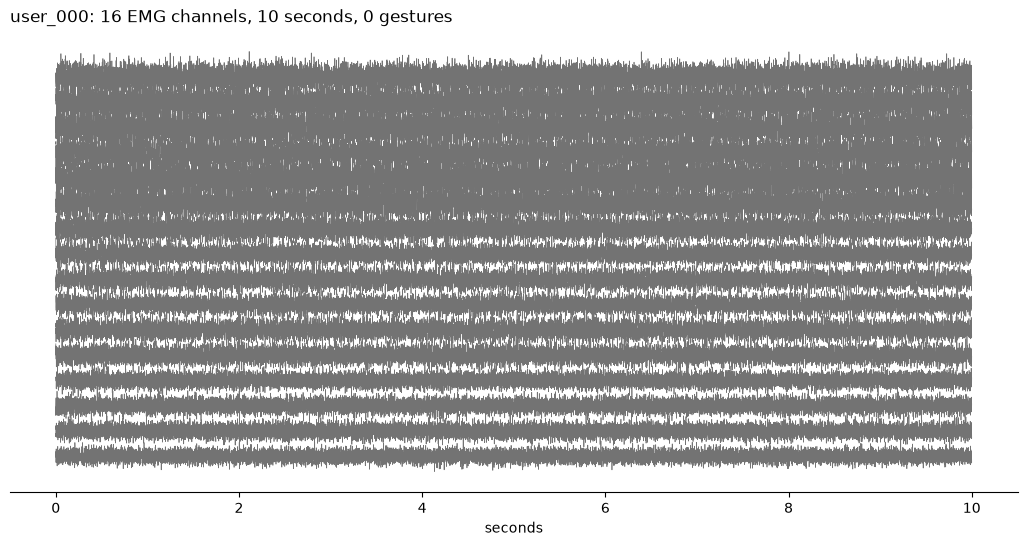

In [2]:
user = "user_000"     # try user_001, user_002
minute = 3            # which minute of their session to show

path, start, end = test_partitions()[user]
rec = load_recording(path, start + minute * 60, start + minute * 60 + 10, user)  # 10 seconds
t = rec.times - rec.times[0]
colors = dict(zip(GESTURES, plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(13, 6))
gap = 4 * rec.emg.std()
for ch in range(16):
    ax.plot(t, rec.emg[ch] + ch * gap, lw=0.5, color="0.45")
for _, g in rec.prompts.iterrows():
    x = g.time - rec.times[0]
    ax.axvline(x, color=colors[g["name"]], lw=1.5)
    ax.text(x, 16 * gap, g["name"].replace("_", " "), rotation=90, fontsize=8,
            ha="right", va="bottom", color=colors[g["name"]])
ax.set_yticks([]); ax.set_xlabel("seconds"); ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_title(f"{user}: 16 EMG channels, 10 seconds, {len(rec.prompts)} gestures", loc="left")
plt.show()

## 2 · The official baseline (already computed)
Meta's test set has **10 people** the model never saw in training. The organizers ran
the model on all 10 (that takes about an hour on Colab, so it's done for you). Your
download has only 3 of them, which you'll reproduce in step 4.

This cell makes the chart that goes into the demo. Make it yours: colours, title,
labels, sorting. Then re-run it.

Mean CLER over 10 test users: 0.1819  ->  gesture accuracy 81.8%


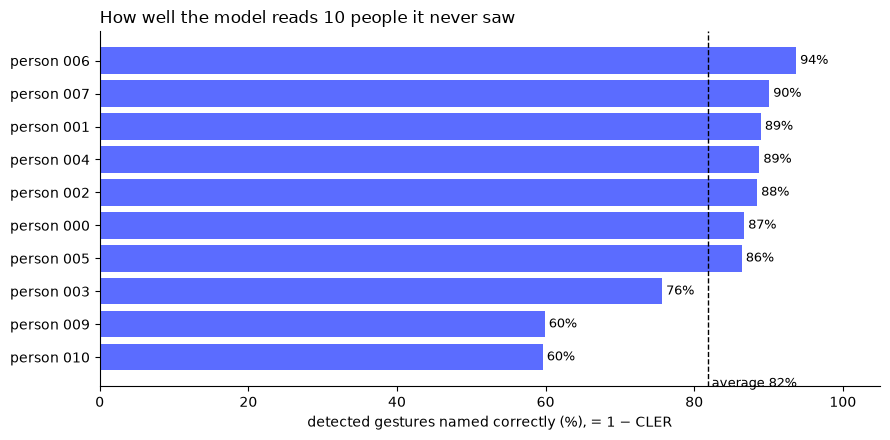

,user,cler,accuracy,gestures,minutes,cpu_seconds
0,user_000,0.133,0.867,1900,39.609,31.680
1,user_001,0.111,0.889,1181,28.633,21.438
2,user_002,0.116,0.884,1900,42.318,33.119
3,user_003,0.243,0.757,1166,24.107,18.240
4,user_004,0.113,0.887,1900,42.243,32.743
5,user_005,0.136,0.864,1170,28.018,21.979
6,user_006,0.063,0.937,1900,41.364,32.386
7,user_007,0.099,0.901,1171,31.541,24.495
8,user_009,0.401,0.599,1178,31.465,24.343
9,user_010,0.404,0.596,837,26.035,19.966


In [3]:
import io
BASELINE = pd.read_csv(io.StringIO("""user,cler,accuracy,gestures,minutes,cpu_seconds
user_000,0.13297878791922013,0.8670212120807799,1900,39.609450240929924,31.680158041999675
user_001,0.11055607428156448,0.8894439257184356,1181,28.63259024620056,21.437706249998882
user_002,0.11559512435035064,0.8844048756496493,1900,42.318006118138634,33.11877575004473
user_003,0.24343593720539566,0.7565640627946043,1166,24.107201409339904,18.240270209033042
user_004,0.11257762592279387,0.8874223740772061,1900,42.24250781536102,32.743149667046964
user_005,0.1362046744160033,0.8637953255839967,1170,28.018093180656432,21.978852916974574
user_006,0.06313155593287055,0.9368684440671294,1900,41.36388372182846,32.38552679202985
user_007,0.09931806796623932,0.9006819320337607,1171,31.541054884592693,24.4946966660209
user_009,0.4012751448455779,0.5987248551544221,1178,31.465158172448476,24.343126915977336
user_010,0.403972088030059,0.596027911969941,837,26.03479241927465,19.966002499917522
"""))
mean = BASELINE.cler.mean()
print(f"Mean CLER over 10 test users: {mean:.4f}  ->  gesture accuracy {1 - mean:.1%}")

b = BASELINE.sort_values("accuracy")
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(b.user.str.replace("user_", "person "), b.accuracy * 100, color="#5b6cff")
ax.axvline((1 - mean) * 100, color="k", ls="--", lw=1)
ax.text((1 - mean) * 100, -0.9, f" average {(1 - mean):.0%}", fontsize=9)
ax.bar_label(bars, fmt="%.0f%%", padding=3, fontsize=9)
ax.set_xlim(0, 105); ax.set_xlabel("detected gestures named correctly (%), = 1 − CLER")
ax.set_title("How well the model reads 10 people it never saw", loc="left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("handin/per_user_accuracy.png", dpi=150)
plt.show()
BASELINE.round(3)

## 3 · Which gestures does it get wrong? (about 1 min on Colab)
Runs the model on 10 minutes of one person (sampled across their whole session, so
every gesture type shows up) and lines up every true gesture with what the model
predicted, exactly the way CLER counts them.

In [4]:
user = "user_001"     # try user_000, user_002
model = load_model()
rec, probs, pt = predict_sample(model, user, minutes=10)
matches = match_events(detect_events(probs, pt), rec.prompts)

print(f"{user}, 10 sampled minutes: CLER {cler(probs, pt, rec.prompts):.3f}")
print(matches.result.value_counts().to_string(), "\n")
per_gesture = (matches[matches.true != "—"]
               .assign(correct=lambda d: d.result == "correct")
               .groupby("true").correct.mean().sort_values())
per_gesture.mul(100).round(1).rename("% correct").to_frame()

user_001, 10 sampled minutes: CLER 0.114
result
correct          288
missed           202
extra             65
wrong gesture     19 



,% correct
true,
middle_press,10.3
thumb_click,19.2
index_press,20.0
middle_release,55.9
index_release,60.0
thumb_up,68.0
thumb_in,81.0
thumb_down,85.7
thumb_out,96.8


In [5]:
# Confusion: rows = what the person did, columns = what the model said ("—" = nothing)
pd.crosstab(matches.true, matches.predicted)

predicted,index_press,index_release,middle_press,middle_release,thumb_click,thumb_down,thumb_in,thumb_out,thumb_up,—
true,,,,,,,,,,
index_press,12,0,5,0,0,0,0,0,0,43
index_release,0,36,0,0,0,0,0,2,0,22
middle_press,1,0,7,0,0,0,0,0,0,60
middle_release,0,0,0,38,0,0,0,0,0,30
thumb_click,0,1,0,0,5,0,2,0,0,18
thumb_down,0,0,0,0,1,48,0,0,0,7
thumb_in,0,0,0,0,0,1,47,0,0,10
thumb_out,0,0,0,0,0,0,0,61,2,0
thumb_up,0,0,0,0,0,0,2,2,34,12


## 4 · Reproduce the baseline on your 3 users
By default this is a **quick check** (5 sampled minutes per person, about 2 min on
Colab), which should give **0.0745**. For the real reproduction, set `RUN_FULL = True`
and run it again. It takes about 16 min on Colab and should give **0.1197**
(0.1330 / 0.1106 / 0.1156). Work on your findings while it runs.

In [6]:
RUN_FULL = False   # <- True for the full 3-user reproduction (~16 min on Colab)

df = evaluate(load_model(), users=USERS, minutes=None if RUN_FULL else QUICK_MINUTES)
expected = 0.1197 if RUN_FULL else 0.0745
print(f"\nMean CLER: {df.cler.mean():.4f}  (expected {expected}, "
      f"{'full sessions' if RUN_FULL else 'quick check'})")
df.to_csv("handin/baseline_3users.csv", index=False)
df.round(4)

user_000: CLER 0.0768  (291 gestures, 5.0 min of EMG, 4.0s on CPU)


user_001: CLER 0.1339  (299 gestures, 5.0 min of EMG, 3.9s on CPU)


user_002: CLER 0.0128  (212 gestures, 5.0 min of EMG, 4.0s on CPU)

Mean CLER: 0.0745  (expected 0.0745, quick check)


,user,cler,accuracy,gestures,minutes,cpu_seconds
0,user_000,0.0768,0.9232,291,5.0,3.9864
1,user_001,0.1339,0.8661,299,5.0,3.9440
2,user_002,0.0128,0.9872,212,5.0,4.0423


## 5 · Your findings (for the final slide)
Write 3 short findings in the cell below, then run it. Ideas to look into:
- Two people (009 and 010) are far worse than the rest. What could make someone harder
  to read? (Arm size, how they wear the band, how they make the gesture…)
- Which gestures are easy and which get confused with each other (step 3)?
- How many gestures does the model miss entirely? CLER ignores those. Does the headline
  number tell the whole story?
- Is 82% good enough for a product? What would a user feel at that error rate?

In [7]:
findings = """
1. ...
2. ...
3. ...
"""
open("handin/findings.md", "w").write(findings.strip() + "\n")
print(findings)


1. ...
2. ...
3. ...



## 6 · Hand in

In [8]:
# Download your hand-in files (they also stay in the handin/ folder on the left).
print(f"⏱ Whole notebook so far: {time.time() - _T0:.0f} s")
import shutil
files_to_send = ['handin/per_user_accuracy.png', 'handin/findings.md']
missing = [f for f in files_to_send if not os.path.exists(f)]
if missing:
    print("Not made yet:", missing)
elif IN_COLAB:
    from google.colab import files
    for f in files_to_send:
        files.download(f)
else:
    print("Saved:", files_to_send)

⏱ Whole notebook so far: 22 s
Saved: ['handin/per_user_accuracy.png', 'handin/findings.md']
